In [1]:
from pybaseball import statcast

In [2]:
data = statcast(
    start_dt="2026-10-01",
    end_dt="2026-10-01"
)


This is a large query, it may take a moment to complete


100%|█████████████████████████████████████| 1/1 [00:00<00:00,  3.57it/s]


In [3]:
print(data.shape)
data.head()

(277, 119)


,pitch_type,game_date,release_speed,release_pos_x,release_pos_z,player_name,batter,pitcher,events,description,...,batter_days_until_next_game,api_break_z_with_gravity,api_break_x_arm,api_break_x_batter_in,arm_angle,attack_angle,attack_direction,swing_path_tilt,intercept_ball_minus_batter_pos_x_inches,intercept_ball_minus_batter_pos_y_inches
99,SL,2026-10-01,80.5,3.1,4.78,"Sale, Chris",805249,519242,strikeout,swinging_strike,...,<NA>,3.72,-1.3,1.3,11.9,33.929716,-66.941943,33.961925,19.84513,66.542933
105,FF,2026-10-01,98.1,3.09,4.85,"Sale, Chris",805249,519242,NaN,ball,...,<NA>,1.48,1.07,-1.07,10.9,<NA>,<NA>,<NA>,<NA>,<NA>
111,SL,2026-10-01,78.3,3.08,4.89,"Sale, Chris",805249,519242,NaN,foul,...,<NA>,4.26,-1.02,1.02,13.2,9.779124,-7.785523,31.977134,33.052141,40.908104
114,SL,2026-10-01,78.6,3.16,4.8,"Sale, Chris",805249,519242,NaN,ball,...,<NA>,3.96,-1.2,1.2,9.5,<NA>,<NA>,<NA>,<NA>,<NA>
118,SL,2026-10-01,78.8,3.22,4.81,"Sale, Chris",805249,519242,NaN,called_strike,...,<NA>,4.17,-0.94,0.94,9.9,<NA>,<NA>,<NA>,<NA>,<NA>


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 277 entries, 99 to 268
Columns: 119 entries, pitch_type to intercept_ball_minus_batter_pos_y_inches
dtypes: Float64(43), Int64(59), datetime64[ns](1), object(16)
memory usage: 287.3+ KB


In [5]:
columns = [
    "pitch_type",       # 球種
    "release_speed",    # 球速
    "release_spin_rate",# 回転数
    "pfx_x",            # 横方向の変化量
    "pfx_z",            # 縦方向の変化量
    "description",      # 投球結果の説明
    "events",           # 打席結果
    "launch_speed",     # 打球速度
    "launch_angle"      # 打球角度
]

display(data[[c for c in columns if c in data.columns]].head(10))

,pitch_type,release_speed,release_spin_rate,pfx_x,pfx_z,description,events,launch_speed,launch_angle
99,SL,80.5,2641,-1.3,-0.19,swinging_strike,strikeout,<NA>,<NA>
105,FF,98.1,2340,1.07,0.9,ball,NaN,<NA>,<NA>
111,SL,78.3,2645,-1.02,-0.53,foul,NaN,84.1,-26
114,SL,78.6,2621,-1.2,-0.29,ball,NaN,<NA>,<NA>
118,SL,78.8,2571,-0.94,-0.5,called_strike,NaN,<NA>,<NA>
125,FF,97.0,2430,1.18,0.89,swinging_strike,strikeout,<NA>,<NA>
130,SL,82.1,2588,-1.03,-0.3,blocked_ball,NaN,<NA>,<NA>
136,FF,97.5,2441,1.3,0.68,ball,NaN,<NA>,<NA>
145,FF,97.8,2323,1.05,0.91,foul,NaN,<NA>,<NA>
160,SL,78.4,2437,-1.25,-0.29,called_strike,NaN,<NA>,<NA>


In [6]:
swinging_strikes = [
    "swinging_strike",
    "swinging_strike_blocked"
]

In [7]:
data["is_swinging_strike"] = (
    data["description"].isin(swinging_strikes)
)

In [8]:
result = (
    data.dropna(subset=["pitch_type"])
    .groupby("pitch_type")
    .agg(
        投球数=("pitch_type", "size"),
        空振り数=("is_swinging_strike", "sum"),
        空振り率=("is_swinging_strike", "mean")
    )
)

In [9]:
result["空振り率"] = result["空振り率"] * 100

In [10]:
result = result.sort_values("投球数", ascending=False)

In [11]:
display(result.round(2))

,投球数,空振り数,空振り率
pitch_type,,,
FF,87,14,16.09
SI,53,2,3.77
FC,29,4,13.79
SL,28,4,14.29
FS,24,2,8.33
CU,22,1,4.55
CH,18,1,5.56
KC,10,1,10.00
ST,5,1,20.00


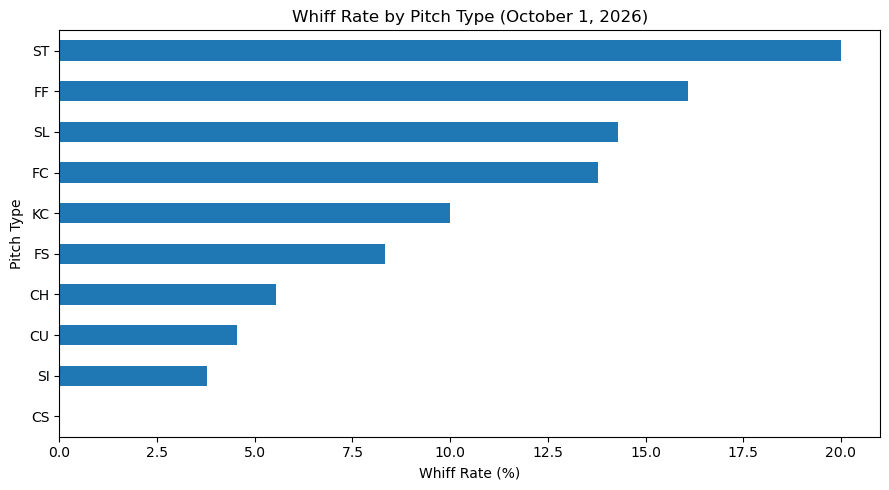

In [13]:
import matplotlib.pyplot as plt

result["空振り率"].sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.xlabel("Whiff Rate (%)")
plt.ylabel("Pitch Type")
plt.title("Whiff Rate by Pitch Type (October 1, 2026)")
plt.tight_layout()
plt.show()